# 9.C.2. Сравнение стратегий на синтетике

В 9.C.1 на коротком реальном ряде стратегии оказались почти равны. Чтобы увидеть, **чем** они
отличаются, нужен эксперимент, где известна «правда» и можно управлять шумом.

Идея: синусоида с шумом в train, а тестовый хвост — **без шума**.
Модель, которая выучила шум, вместо формы сигнала будет наказана.

Сравниваем четыре стратегии — рекурсивную, прямую, MIMO и DIRMO — на одном регрессоре
(CatBoost). Каждое число — среднее по 5 сидам шума: на одном сиде порядок стратегий случаен.

In [1]:
import common  # первым: глушит предупреждения библиотек при импорте

common.quiet()

import time  # noqa: E402

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from catboost import CatBoostRegressor  # noqa: E402
from sktime.forecasting.base import ForecastingHorizon  # noqa: E402
from sktime.forecasting.compose import make_reduction  # noqa: E402
from sktime.forecasting.compose._reduce import _sliding_window_transform  # noqa: E402

PERIOD, N_TRAIN, H = 30, 300, 30
SEEDS = range(5)
SEGMENTS = {"h 1–5": slice(0, 5), "h 6–15": slice(5, 15), "h 16–30": slice(15, 30)}
fh = ForecastingHorizon(np.arange(1, H + 1))

## 0. Синтетика

Два вида шума:
- **аддитивный**: `sin(2πt/30) + ε` — значения «дрожат» вокруг синусоиды;
- **фазовый**: `sin(2πt/30 + ε)` — значения всегда на синусоиде, но «скачут» по фазе.

Тест в обоих случаях — чистая `sin(2πt/30)`.

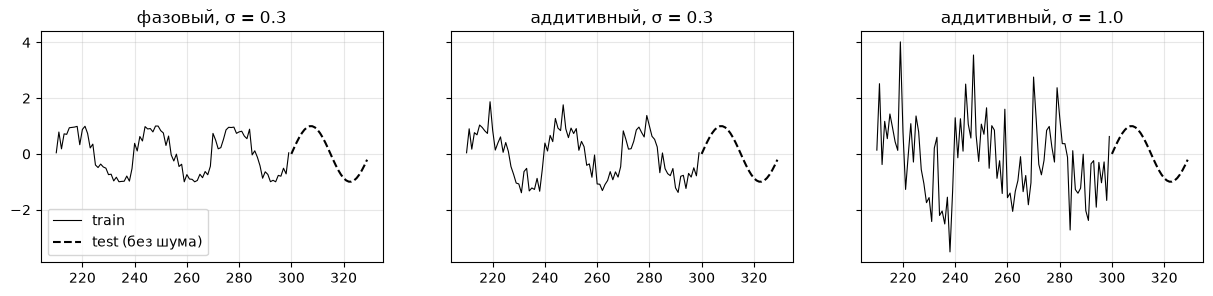

In [2]:
def make_series(kind, noise, seed):
    """Train: синусоида с шумом (N_TRAIN точек). Test: следующие H точек чистой синусоиды."""
    rng = np.random.default_rng(seed)
    t = np.arange(N_TRAIN + H)
    eps = rng.normal(0, noise, t.size)
    clean = np.sin(2 * np.pi * t / PERIOD)
    noisy = np.sin(2 * np.pi * t / PERIOD + eps) if kind == "фазовый" else clean + eps
    return pd.Series(noisy[:N_TRAIN]), clean[N_TRAIN:]


fig, axes = plt.subplots(1, 3, figsize=(15, 3), sharey=True)
for ax, (kind, noise) in zip(axes, [("фазовый", 0.3), ("аддитивный", 0.3), ("аддитивный", 1.0)]):
    train, test = make_series(kind, noise, seed=0)
    ax.plot(np.arange(N_TRAIN - 90, N_TRAIN), train.iloc[-90:], color="black", lw=0.8, label="train")
    ax.plot(np.arange(N_TRAIN, N_TRAIN + H), test, color="black", ls="--", label="test (без шума)")
    ax.set_title(f"{kind}, σ = {noise}")
    ax.grid(alpha=0.3)
axes[0].legend(loc="lower left");

### Стратегии

Рекурсивная, прямая и MIMO — из sktime (в 9.C.1 проверено, что они совпадают с ручными),
DIRMO — та же функция, что в 9.C.1.

In [3]:
def make_catboost(**kwargs):
    return CatBoostRegressor(iterations=300, depth=4, random_seed=0, verbose=False, thread_count=4, **kwargs)


def sktime_strategy(strategy, multi=False):
    def forecast(y, window):
        estimator = make_catboost(loss_function="MultiRMSE") if multi else make_catboost()
        forecaster = make_reduction(estimator, strategy=strategy, window_length=window)
        return forecaster.fit(y, fh=fh).predict().to_numpy()

    return forecast


def dirmo(s):
    def forecast(y, window):
        yt, Xt = _sliding_window_transform(y, window_length=window, fh=fh)
        last_window = y.to_numpy()[-window:].reshape(1, -1)
        blocks = []
        for start in range(0, H, s):
            if s == 1:
                model = make_catboost().fit(Xt, yt[:, start])
            else:
                model = make_catboost(loss_function="MultiRMSE").fit(Xt, yt[:, start : start + s])
            blocks.append(np.atleast_1d(model.predict(last_window).ravel()))
        return np.concatenate(blocks)

    return forecast


STRATEGIES = {
    "рекурсивная": sktime_strategy("recursive"),
    "прямая": sktime_strategy("direct"),
    "MIMO": sktime_strategy("multioutput", multi=True),
    "DIRMO, s=10": dirmo(10),
}


def evaluate(strategies, kind, noise, window):
    """Для каждой стратегии: средняя по сидам абсолютная ошибка на каждом шаге горизонта и время."""
    errors, timings, examples = {}, {}, {}
    for name, forecast in strategies.items():
        per_seed, seconds = [], []
        for seed in SEEDS:
            y, clean = make_series(kind, noise, seed)
            start = time.perf_counter()
            pred = forecast(y, window)
            seconds.append(time.perf_counter() - start)
            per_seed.append(np.abs(pred - clean))
            if seed == 0:
                examples[name] = pred
        errors[name] = np.mean(per_seed, axis=0)  # MAE по шагам горизонта
        timings[name] = np.mean(seconds)
    return errors, timings, examples


def segment_table(errors):
    table = pd.DataFrame({name: {seg: e[s].mean() for seg, s in SEGMENTS.items()} for name, e in errors.items()}).T
    table.insert(0, "MAE", [e.mean() for e in errors.values()])
    return table.round(3)

## 1. Основное сравнение: окно = период (W = 30)

In [4]:
CASES = [("фазовый", 0.3), ("аддитивный", 0.3), ("аддитивный", 1.0)]
runs = {case: evaluate(STRATEGIES, *case, window=30) for case in CASES}

pd.DataFrame({f"{kind}, σ={noise}": {name: e.mean() for name, e in runs[(kind, noise)][0].items()} for kind, noise in CASES}).round(3)

,"фазовый, σ=0.3","аддитивный, σ=0.3","аддитивный, σ=1.0"
рекурсивная,0.099,0.117,0.349
прямая,0.104,0.130,0.346
MIMO,0.066,0.074,0.180
"DIRMO, s=10",0.067,0.070,0.184


In [5]:
pd.Series(runs[("аддитивный", 1.0)][1], name="время на один прогноз, с").round(2)

рекурсивная    0.13
прямая         3.50
MIMO           2.06
DIRMO, s=10    1.92
Name: время на один прогноз, с, dtype: float64

- **MIMO и DIRMO лучше во всех трёх постановках**, при сильном шуме — почти вдвое. Одна модель
  видит все 30 шагов сразу: в каждом листе дерева лежит средний вектор будущего по многим окнам,
  и шум отдельных точек усредняется. Прогноз получается «формой», а не отдельными точками.
- **Прямая** учит 30 независимых моделей, каждая — на своём шумном столбце, и каждая переобучается
  на свой шум. При этом она примерно в 25 раз дороже рекурсии.
- **Рекурсивная** здесь не хуже прямой. Причина в окне: W = 30 = период, поэтому для шага `t+1`
  в окне есть `y(t-29)` — значение ровно период назад. Модель учит что-то близкое к «повтори
  сглаженный прошлый цикл», а такая модель не накапливает ошибку.

Посмотрим на сами прогнозы (сид 0, аддитивный шум σ = 1.0):

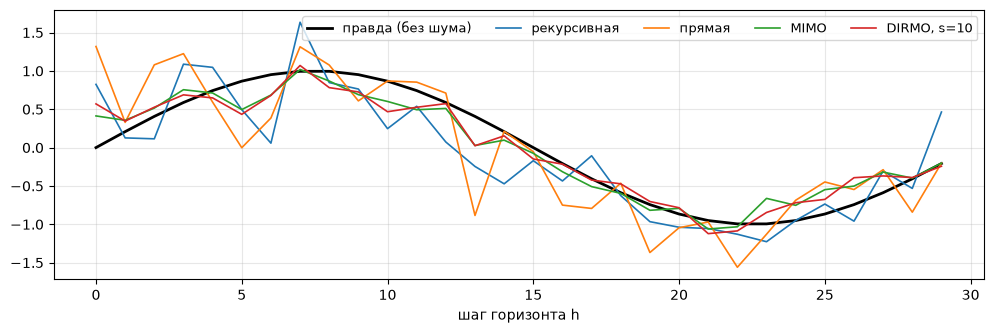

In [5]:
errors, _, examples = runs[("аддитивный", 1.0)]
_, clean = make_series("аддитивный", 1.0, seed=0)
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(clean, color="black", lw=2, label="правда (без шума)")
for name, pred in examples.items():
    ax.plot(pred, lw=1.2, label=name)
ax.legend(ncol=5, fontsize=9)
ax.set_xlabel("шаг горизонта h")
ax.grid(alpha=0.3);

Прямая стратегия — «рваная» кривая: соседние шаги предсказывают разные модели, никак не связанные
(Ben Taieb et al., §2.2). MIMO — гладкая, согласованная по шагам.

## 2. Окно короче периода: накопление ошибки рекурсией

Уменьшим окно до W = 10 (треть периода). Теперь для рекурсии в окне нет «прошлого цикла» — модель
должна сама «вести» синусоиду по своим же прогнозам.

In [6]:
short_errors, _, _ = evaluate(STRATEGIES, "аддитивный", 0.3, window=10)
segment_table(short_errors)

,MAE,h 1–5,h 6–15,h 16–30
рекурсивная,0.324,0.357,0.252,0.361
прямая,0.177,0.214,0.161,0.175
MIMO,0.132,0.164,0.103,0.141
"DIRMO, s=10",0.132,0.147,0.104,0.146


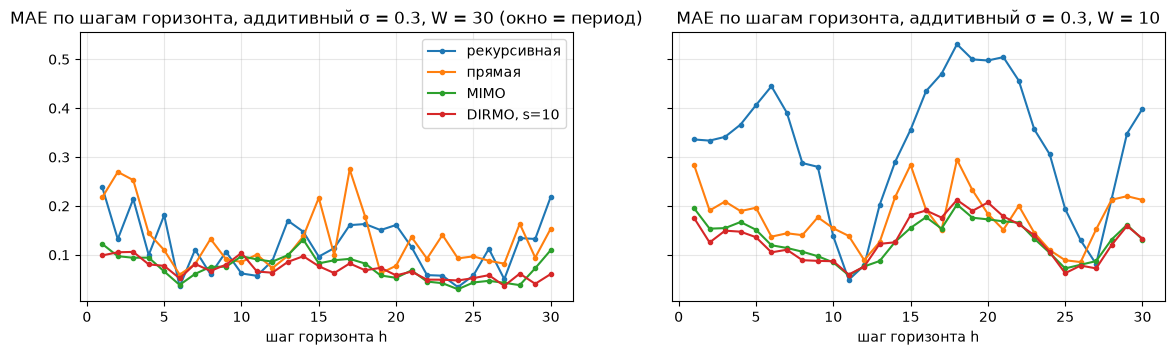

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5), sharey=True)
for ax, (title, errs) in zip(axes, [("W = 30 (окно = период)", runs[("аддитивный", 0.3)][0]), ("W = 10", short_errors)]):
    for name, e in errs.items():
        ax.plot(np.arange(1, H + 1), e, marker=".", label=name)
    ax.set_title(f"MAE по шагам горизонта, аддитивный σ = 0.3, {title}")
    ax.set_xlabel("шаг горизонта h")
    ax.grid(alpha=0.3)
axes[0].legend();

С коротким окном рекурсия становится худшей стратегией — в 2.5 раза хуже MIMO. Ошибки первых шагов
попадают в окно и переносятся на следующие. Растёт она при этом не монотонно, а волнами: ошибка
максимальна вокруг пиков и впадин синусоиды — по 10 точкам, часть из которых её же прогнозы,
модель плохо «ведёт» кривизну. Прямая и MIMO от длины окна страдают гораздо меньше: они никогда
не подставляют свои прогнозы на вход.

Вывод: «рекурсия накапливает ошибку» верно не всегда — это зависит от того, насколько окно
описывает динамику ряда. Длина окна — такой же важный гиперпараметр, как выбор стратегии.

## 3. DIRMO: от прямой к MIMO

Размер блока `s` плавно переводит DIRMO от прямой стратегии (`s = 1`) к MIMO (`s = H`).

In [8]:
sweep = {f"s={s}": dirmo(s) for s in (1, 3, 5, 10, 15, 30)}
sweep_errors, sweep_times, _ = evaluate(sweep, "аддитивный", 1.0, window=30)
sweep_table = pd.DataFrame(
    {"MAE": {k: e.mean() for k, e in sweep_errors.items()}, "моделей": {k: H // int(k[2:]) for k in sweep}, "время, с": sweep_times}
)
sweep_table.round(3)

,MAE,моделей,"время, с"
s=1,0.346,30,4.002
s=3,0.214,10,2.445
s=5,0.193,6,2.024
s=10,0.184,3,1.967
s=15,0.194,2,1.782
s=30,0.180,1,2.020


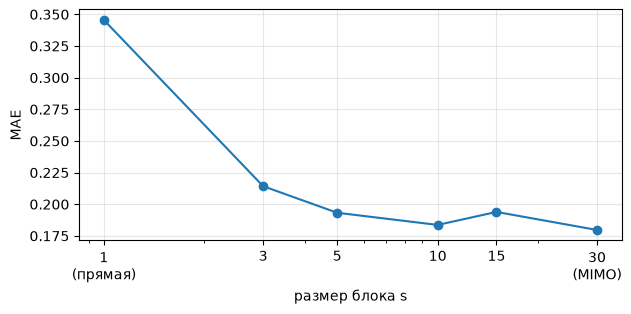

In [9]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot([int(k[2:]) for k in sweep], sweep_table["MAE"], marker="o")
ax.set_xlabel("размер блока s")
ax.set_ylabel("MAE")
ax.set_xscale("log")
ax.set_xticks([1, 3, 5, 10, 15, 30], ["1\n(прямая)", "3", "5", "10", "15", "30\n(MIMO)"])
ax.grid(alpha=0.3);

Главный скачок — уже от `s = 1` к `s = 3`: стоит нескольким шагам делить одни деревья, и шум
начинает усредняться. Дальше MAE почти не меняется (колебания в пределах шума по сидам), а модель
становится дешевле: 30 моделей при `s = 1` против одной при `s = 30`.

## 4. Итоги

Статья Ben Taieb et al. (NN5, 111 реальных рядов) приходит к тому же: MIMO-семейство в среднем
лучше одношаговых стратегий. Синтетика показывает, **почему**: при шуме выигрывает тот, кто
предсказывает форму горизонта целиком.

Шпаргалка выбора стратегии:

| Ситуация | Стратегия |
|---|---|
| короткий горизонт, окно покрывает сезон, мало шума | рекурсивная — дёшево и точно |
| признаки, известные на весь горизонт; дешёвый прод; много рядов | упрощённая прямая (`Pipeline` в ETNA) |
| длинный горизонт, шумный ряд | MIMO / DIRMO (нужен регрессор с многомерным выходом) |
| нужна свежая информация для ближних шагов | `DirectEnsemble` блоками горизонта |
| чистая прямая на каждый шаг | почти никогда: дорого, шумно, «рваный» прогноз |

И главное: на коротком реальном ряде (9.C.1) разница стратегий тонет в шуме, а предобработка
(детрендинг) и длина окна важнее выбора стратегии.